Mounted at /content/drive
                  metric  pixel  px lo  px hi  building  bld lo  bld hi
      xView2-style score  0.415  0.393  0.435     0.443   0.422   0.460
         Localisation F1  0.725  0.719  0.731     0.758   0.748   0.767
    Damage F1: no damage  0.622  0.594  0.648     0.590   0.550   0.629
        Damage F1: minor  0.288  0.264  0.310     0.253   0.226   0.277
        Damage F1: major  0.513  0.471  0.549     0.462   0.408   0.517
    Damage F1: destroyed  0.140  0.113  0.170     0.194   0.155   0.233
Damage F1: harmonic mean  0.282  0.252  0.311     0.309   0.278   0.332


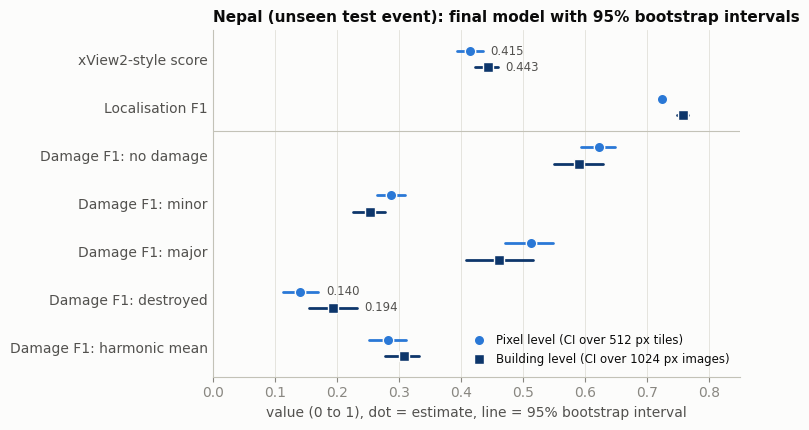

saved figures/fig10_nepal_intervals.png


In [1]:
# Figure 10: Nepal test, final model, 95% bootstrap intervals (pixel vs building).
# Needs only Drive (no GPU, no repo): reads eval_extras/nepal_final/nepal_metrics.json.
import json
import os

import matplotlib as mpl
import matplotlib.pyplot as plt
import pandas as pd

try:
    from google.colab import drive
    drive.mount("/content/drive")
    D = "/content/drive/MyDrive/MAAI 902 X 901 PROJECT"
except ImportError:                      # local test
    D = os.environ.get("FV_DRIVE", "/tmp/fvdrive")
SRC = f"{D}/eval_extras/nepal_final/nepal_metrics.json"
FIG = f"{D}/figures"
os.makedirs(FIG, exist_ok=True)
J = json.load(open(SRC))
PX, BL = J["pixel_bootstrap_95"], J["building_bootstrap_95"]

ROWS = [  # (label, pixel key, building key)
    ("xView2-style score", "xview2_pixel_score", "xview2_building_score"),
    ("Localisation F1", "loc_f1", "loc_f1"),
    ("Damage F1: no damage", "dmg_f1_no_damage", "dmg_f1_no_damage"),
    ("Damage F1: minor", "dmg_f1_minor", "dmg_f1_minor"),
    ("Damage F1: major", "dmg_f1_major", "dmg_f1_major"),
    ("Damage F1: destroyed", "dmg_f1_destroyed", "dmg_f1_destroyed"),
    ("Damage F1: harmonic mean", "damage_f1_hm", "damage_f1_hm"),
]
T = pd.DataFrame([{"metric": lab,
                   "pixel": PX[p]["value"], "px lo": PX[p]["lo"], "px hi": PX[p]["hi"],
                   "building": BL[b]["value"], "bld lo": BL[b]["lo"], "bld hi": BL[b]["hi"]}
                  for lab, p, b in ROWS])
print(T.round(3).to_string(index=False))

# Same style as figures 1-9. One model (M1 weighted CE = the blue used for it in every figure);
# the two levels are two steps of that blue AND two marker shapes, so colour is never the only cue.
SURF, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
C_PX, C_BL = "#2a78d6", "#0d366b"
mpl.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK, "xtick.color": MUTED,
    "ytick.color": INK2, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "legend.frameon": False})

fig, ax = plt.subplots(figsize=(7.6, 4.4))
n = len(T)
y = list(range(n))[::-1]                 # first row at the top
off = 0.17
for i, r in T.iterrows():
    yi = y[i]
    for val, lo, hi, dy, c, mk, lab in [
            (r["pixel"], r["px lo"], r["px hi"], +off, C_PX, "o", "Pixel level (CI over 512 px tiles)"),
            (r["building"], r["bld lo"], r["bld hi"], -off, C_BL, "s", "Building level (CI over 1024 px images)")]:
        ax.plot([lo, hi], [yi + dy, yi + dy], color=c, lw=2, solid_capstyle="round", zorder=2)
        ax.plot(val, yi + dy, marker=mk, ms=7.5, color=c, mec=SURF, mew=1.0, ls="none", zorder=3,
                label=lab if i == 0 else None)
    if i in (0, 5):                      # selective direct labels: headline score and the weakest class
        for val, hi, dy, c in [(r["pixel"], r["px hi"], +off, C_PX), (r["building"], r["bld hi"], -off, C_BL)]:
            ax.text(hi + 0.012, yi + dy, f"{val:.3f}", va="center", ha="left", fontsize=8.5, color=INK2)
ax.axhline(y[1] - 0.5, color=AXIS, lw=0.8)  # separate the two summary rows from per-class damage F1
ax.set_yticks(y)
ax.set_yticklabels(T["metric"])
ax.tick_params(axis="y", length=0)
ax.grid(axis="y", visible=False)
ax.set_xlim(0, 0.85)
ax.set_ylim(-0.6, n - 0.4)
ax.set_xlabel("value (0 to 1), dot = estimate, line = 95% bootstrap interval")
ax.set_title("Nepal (unseen test event): final model with 95% bootstrap intervals", loc="left")
ax.legend(loc="lower right", fontsize=8.5, handlelength=1.2)
fig.tight_layout()
fig.savefig(f"{FIG}/fig10_nepal_intervals.png", dpi=200, bbox_inches="tight")
plt.show()
print("saved figures/fig10_nepal_intervals.png")